In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/amirhossein078/heartcsv/heart.csv


In [2]:
import matplotlib.pyplot as plt
import pandas as pd
df = pd.read_csv("/kaggle/input/datasets/amirhossein078/heartcsv/heart.csv")
df.isnull().sum()
df.head()

,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [3]:
x = df.drop(columns=['output'])
y = df['output']

In [4]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
x_train.shape, x_test.shape, y_train.shape, y_test.shape

((242, 13), (61, 13), (242,), (61,))

In [5]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, jaccard_score, classification_report
for criterion in ['entropy','gini','log_loss']:
    try:
        model = DecisionTreeClassifier(criterion=criterion,max_depth=4)
        model.fit(x_train, y_train)
        predict = model.predict(x_test)
        acc = accuracy_score(y_test, predict)
        ja = jaccard_score(y_test, predict, pos_label=0)
        f1 = f1_score(y_test, predict, average='weighted')
        print("criterion: ",criterion,"\njaccard score: ",ja,"\nf1 score: ",f1,"\naccuracy score: ",acc,"\n")
    except Exception as e:
        print("Error: ",e)

criterion:  entropy 
jaccard score:  0.7878787878787878 
f1 score:  0.8853076471859467 
accuracy score:  0.8852459016393442 

criterion:  gini 
jaccard score:  0.7428571428571429 
f1 score:  0.8524590163934426 
accuracy score:  0.8524590163934426 

criterion:  log_loss 
jaccard score:  0.7878787878787878 
f1 score:  0.8853076471859467 
accuracy score:  0.8852459016393442 



              precision    recall  f1-score   support

           0       0.87      0.90      0.88        29
           1       0.90      0.88      0.89        32

    accuracy                           0.89        61
   macro avg       0.88      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



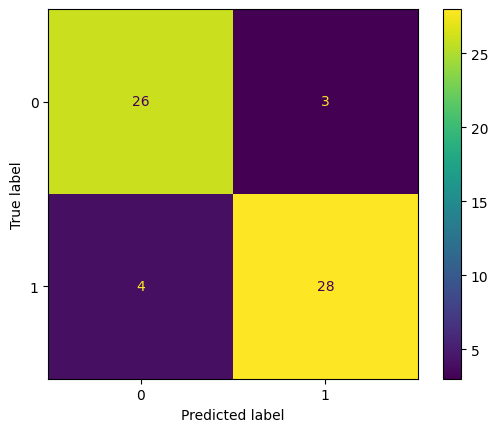

In [6]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
model = DecisionTreeClassifier(criterion='entropy',max_depth=4)
model.fit(x_train, y_train)
predict = model.predict(x_test)

cm = confusion_matrix(y_test, predict)
display = ConfusionMatrixDisplay(confusion_matrix=cm)
print (classification_report(y_test, predict))
display.plot()
plt.show()

accuracy_score:  0.8524590163934426 
r2_score:  0.8615384615384616 
jaccard_score:  0.7567567567567568 

              precision    recall  f1-score   support

           0       0.86      0.83      0.84        29
           1       0.85      0.88      0.86        32

    accuracy                           0.85        61
   macro avg       0.85      0.85      0.85        61
weighted avg       0.85      0.85      0.85        61



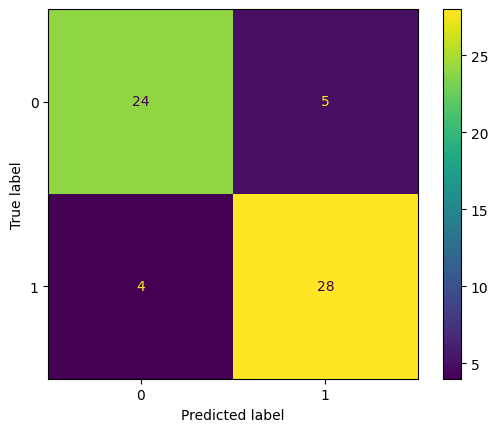

In [7]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(n_estimators=100,criterion='gini')
model.fit(x_train, y_train)
predict = model.predict(x_test)
acc = accuracy_score(y_test, predict)
f1  = f1_score(y_test, predict)
ja = jaccard_score(y_test, predict)
print("accuracy_score: ",acc,"\nr2_score: ",f1,"\njaccard_score: ",ja,"\n")

cm = confusion_matrix(y_test, predict)
display = ConfusionMatrixDisplay(confusion_matrix=cm)
print (classification_report(y_test, predict))
display.plot()
plt.show()

In [8]:
from sklearn.svm import SVC
for kernel in ['rbf','poly','linear','sigmoid']:
    try:
        clf = SVC(kernel=kernel).fit(x_train, y_train)
        model = SVC(kernel=kernel)
        model.fit(x_train, y_train)
        predict = model.predict(x_test)
        acc = accuracy_score(y_test, predict)
        f1  = f1_score(y_test, predict)
        ja = jaccard_score(y_test, predict)
        print("kernel: ",kernel,"\njaccard score: ",ja,"\nf1 score: ",f1,"\naccuracy score: ",acc,"\n")
    except Exception as e:
        print("Error: ",e)

kernel:  rbf 
jaccard score:  0.6086956521739131 
f1 score:  0.7567567567567568 
accuracy score:  0.7049180327868853 

kernel:  poly 
jaccard score:  0.6585365853658537 
f1 score:  0.7941176470588235 
accuracy score:  0.7704918032786885 

kernel:  linear 
jaccard score:  0.7777777777777778 
f1 score:  0.875 
accuracy score:  0.8688524590163934 

kernel:  sigmoid 
jaccard score:  0.5245901639344263 
f1 score:  0.6881720430107527 
accuracy score:  0.5245901639344263 



              precision    recall  f1-score   support

           0       0.86      0.86      0.86        29
           1       0.88      0.88      0.88        32

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.87      0.87      0.87        61



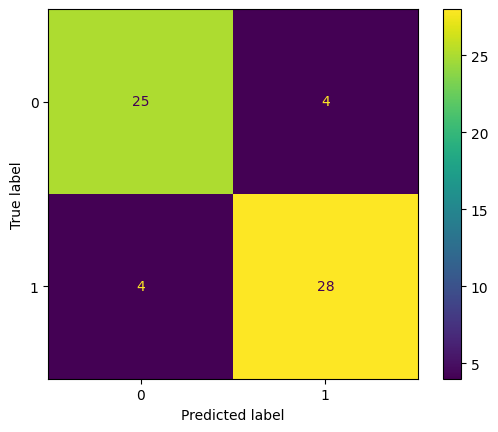

In [9]:
model = SVC(kernel='linear')
model.fit(x_train, y_train)
predict = model.predict(x_test)

cm = confusion_matrix(y_test, predict)
display = ConfusionMatrixDisplay(confusion_matrix=cm)
print (classification_report(y_test, predict))
display.plot()
plt.show()